# FinGuard — Task 1: Data Cleaning & Visualization

**Dataset:** IEEE-CIS Fraud Detection (Kaggle competition, Vesta Corporation)
**Files used:** `train_transaction.csv` + `train_identity.csv` (training split only)
**Key:** `TransactionID` — target `isFraud` (0 = legitimate, 1 = fraud)
**Scope of this task:** load, inspect, assess quality, handle missing values,
remove confirmed duplicates, validate types, LEFT-merge on `TransactionID`,
analyse outliers, run EDA and save visualisations, export the cleaned merged
dataset. **Not in scope (later tasks):** model training, feature selection,
class balancing (SMOTE), train-test splitting, model-specific encoding.

**Data note:** the two CSVs were obtained from the public IEEE-CIS mirror at
`antifraud.pp.ua/downloads/` (same files as the Kaggle competition), because
the Kaggle competition download requires a signed-in account that has accepted
the competition rules. Row/column counts were verified against the official
Kaggle figures (590,540 x 394 and 144,233 x 41). One naming difference in the
mirror is corrected in Section 7: identity columns are `id_01..id_38` there,
vs the canonical Kaggle names `id-01..id-38`. The uploaded `test_identity`
file was **not** used anywhere in this task — test data stays untouched.

Run this notebook from the `notebooks/` folder (all paths below are relative):
`jupyter nbconvert --to notebook --execute Task1_Data_Cleaning_Visualization.ipynb`


## 1. Import Libraries

Core stack: pandas / NumPy for data handling, Matplotlib + Seaborn for
visualisation. `gc` is used to release the large frames once merged, and
`sklearn.impute.SimpleImputer` supplies the median/mode imputation used in
Section 5 (only where the missingness rule justifies it).

In [1]:
import gc
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.style.use("seaborn-v0_8-whitegrid")
sns.set_palette("deep")

# Paths are relative to this notebook (notebooks/ folder)
BASE_DIR = Path.cwd()
DATA_DIR = (BASE_DIR / ".." / "data").resolve()
VIZ_DIR = (BASE_DIR / ".." / "visualizations").resolve()
OUT_DIR = (BASE_DIR / ".." / "cleaned_data").resolve()
VIZ_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

TXN_PATH = DATA_DIR / "train_transaction.csv"
IDENT_PATH = DATA_DIR / "train_identity.csv"
print("Transaction file:", TXN_PATH, "| exists:", TXN_PATH.exists())
print("Identity file:   ", IDENT_PATH, "| exists:", IDENT_PATH.exists())

LEGIT_COLOR = "#2E86AB"   # blue  - legitimate
FRAUD_COLOR = "#E4572E"   # orange-red - fraud

Transaction file: /home/hatch/workspace/FinGuard/Task-1-Data-Cleaning/data/train_transaction.csv | exists: True
Identity file:    /home/hatch/workspace/FinGuard/Task-1-Data-Cleaning/data/train_identity.csv | exists: True


## 2. Load Dataset

Both CSVs are loaded with default dtypes first (memory is reclaimed by the
downcasting step in Section 7). Shapes, the first five and last five rows of
each file are shown to verify the load.

In [2]:
txn = pd.read_csv(TXN_PATH)
ident = pd.read_csv(IDENT_PATH)

print("train_transaction shape:", txn.shape, "(rows, columns)")
print("train_identity    shape:", ident.shape, "(rows, columns)")
print()
print("--- train_transaction: first 5 rows ---")
display(txn.head())
print("--- train_transaction: last 5 rows ---")
display(txn.tail())
print("--- train_identity: first 5 rows ---")
display(ident.head())
print("--- train_identity: last 5 rows ---")
display(ident.tail())

train_transaction shape: (590540, 394) (rows, columns)
train_identity    shape: (144233, 41) (rows, columns)

--- train_transaction: first 5 rows ---


,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,card6,addr1,addr2,dist1,dist2,...,V325,V326,V327,V328,V329,V330,V331,V332,V333,V334,V335,V336,V337,V338,V339
0,2987000,0,86400,68.5000,W,13926,NaN,150.0000,discover,142.0000,credit,315.0000,87.0000,19.0000,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.0000,W,2755,404.0000,150.0000,mastercard,102.0000,credit,325.0000,87.0000,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.0000,W,4663,490.0000,150.0000,visa,166.0000,debit,330.0000,87.0000,287.0000,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2987003,0,86499,50.0000,W,18132,567.0000,150.0000,mastercard,117.0000,debit,476.0000,87.0000,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2987004,0,86506,50.0000,H,4497,514.0000,150.0000,mastercard,102.0000,credit,420.0000,87.0000,NaN,NaN,...,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


--- train_transaction: last 5 rows ---


,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,card6,addr1,addr2,dist1,dist2,...,V325,V326,V327,V328,V329,V330,V331,V332,V333,V334,V335,V336,V337,V338,V339
590535,3577535,0,15811047,49.0000,W,6550,NaN,150.0000,visa,226.0000,debit,272.0000,87.0000,48.0000,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
590536,3577536,0,15811049,39.5000,W,10444,225.0000,150.0000,mastercard,224.0000,debit,204.0000,87.0000,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
590537,3577537,0,15811079,30.9500,W,12037,595.0000,150.0000,mastercard,224.0000,debit,231.0000,87.0000,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
590538,3577538,0,15811088,117.0000,W,7826,481.0000,150.0000,mastercard,224.0000,debit,387.0000,87.0000,3.0000,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
590539,3577539,0,15811131,279.9500,W,15066,170.0000,150.0000,mastercard,102.0000,credit,299.0000,87.0000,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


--- train_identity: first 5 rows ---


,TransactionID,id_01,id_02,id_03,id_04,id_05,id_06,id_07,id_08,id_09,id_10,id_11,id_12,id_13,id_14,...,id_26,id_27,id_28,id_29,id_30,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
0,2987004,0.0000,"70,787.0000",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.0000,NotFound,NaN,-480.0000,...,NaN,NaN,New,NotFound,Android 7.0,samsung browser 6.2,32.0000,2220x1080,match_status:2,T,F,T,T,mobile,SAMSUNG SM-G892A Build/NRD90M
1,2987008,-5.0000,"98,945.0000",NaN,NaN,0.0000,-5.0000,NaN,NaN,NaN,NaN,100.0000,NotFound,49.0000,-300.0000,...,NaN,NaN,New,NotFound,iOS 11.1.2,mobile safari 11.0,32.0000,1334x750,match_status:1,T,F,F,T,mobile,iOS Device
2,2987010,-5.0000,"191,631.0000",0.0000,0.0000,0.0000,0.0000,NaN,NaN,0.0000,0.0000,100.0000,NotFound,52.0000,NaN,...,NaN,NaN,Found,Found,NaN,chrome 62.0,NaN,NaN,NaN,F,F,T,T,desktop,Windows
3,2987011,-5.0000,"221,832.0000",NaN,NaN,0.0000,-6.0000,NaN,NaN,NaN,NaN,100.0000,NotFound,52.0000,NaN,...,NaN,NaN,New,NotFound,NaN,chrome 62.0,NaN,NaN,NaN,F,F,T,T,desktop,NaN
4,2987016,0.0000,"7,460.0000",0.0000,0.0000,1.0000,0.0000,NaN,NaN,0.0000,0.0000,100.0000,NotFound,NaN,-300.0000,...,NaN,NaN,Found,Found,Mac OS X 10_11_6,chrome 62.0,24.0000,1280x800,match_status:2,T,F,T,T,desktop,MacOS


--- train_identity: last 5 rows ---


,TransactionID,id_01,id_02,id_03,id_04,id_05,id_06,id_07,id_08,id_09,id_10,id_11,id_12,id_13,id_14,...,id_26,id_27,id_28,id_29,id_30,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
144228,3577521,-15.0000,"145,955.0000",0.0000,0.0000,0.0000,0.0000,NaN,NaN,0.0000,0.0000,100.0000,NotFound,27.0000,NaN,...,NaN,NaN,Found,Found,NaN,chrome 66.0 for android,NaN,NaN,NaN,F,F,T,F,mobile,F3111 Build/33.3.A.1.97
144229,3577526,-5.0000,"172,059.0000",NaN,NaN,1.0000,-5.0000,NaN,NaN,NaN,NaN,100.0000,NotFound,27.0000,-300.0000,...,NaN,NaN,New,NotFound,Android 7.1.1,chrome 55.0 for android,32.0000,855x480,match_status:2,T,F,T,F,mobile,A574BL Build/NMF26F
144230,3577529,-20.0000,"632,381.0000",NaN,NaN,-1.0000,-36.0000,NaN,NaN,NaN,NaN,100.0000,NotFound,27.0000,NaN,...,NaN,NaN,New,NotFound,NaN,chrome 65.0 for android,NaN,NaN,NaN,F,F,T,F,mobile,Moto E (4) Plus Build/NMA26.42-152
144231,3577531,-5.0000,"55,528.0000",0.0000,0.0000,0.0000,-7.0000,NaN,NaN,0.0000,0.0000,100.0000,NotFound,27.0000,-300.0000,...,NaN,NaN,Found,Found,Mac OS X 10_9_5,chrome 66.0,24.0000,2560x1600,match_status:2,T,F,T,F,desktop,MacOS
144232,3577534,-45.0000,"339,406.0000",NaN,NaN,-10.0000,-100.0000,NaN,NaN,NaN,NaN,100.0000,NotFound,27.0000,NaN,...,NaN,NaN,New,NotFound,NaN,chrome 66.0 for android,NaN,NaN,NaN,F,F,T,F,mobile,RNE-L03 Build/HUAWEIRNE-L03


## 3. Initial Data Inspection

Column names, data types, the numeric / categorical split, descriptive
statistics for the key (non-anonymised) columns, and unique-value counts for
the categorical columns. The 339 anonymised `V1..V339` features are summarised
as a group instead of printing all of them.

In [3]:
print("Transaction columns (first 40):", list(txn.columns[:40]))
print("Transaction columns (last 10): ", list(txn.columns[-10:]))
print("Identity columns:             ", list(ident.columns))
print()
print("--- Transaction dtypes (count by dtype) ---")
print(txn.dtypes.value_counts())
print()
print("--- Identity dtypes (count by dtype) ---")
print(ident.dtypes.value_counts())

num_cols_txn = txn.select_dtypes(include=[np.number]).columns.tolist()
cat_cols_txn = txn.select_dtypes(exclude=[np.number]).columns.tolist()
num_cols_ident = ident.select_dtypes(include=[np.number]).columns.tolist()
cat_cols_ident = ident.select_dtypes(exclude=[np.number]).columns.tolist()
print(f"\nTransaction: {len(num_cols_txn)} numeric, {len(cat_cols_txn)} categorical")
print("Categorical transaction columns:", cat_cols_txn)
print(f"Identity: {len(num_cols_ident)} numeric, {len(cat_cols_ident)} categorical")
print("Categorical identity columns:", cat_cols_ident)

Transaction columns (first 40): ['TransactionID', 'isFraud', 'TransactionDT', 'TransactionAmt', 'ProductCD', 'card1', 'card2', 'card3', 'card4', 'card5', 'card6', 'addr1', 'addr2', 'dist1', 'dist2', 'P_emaildomain', 'R_emaildomain', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'C8', 'C9', 'C10', 'C11', 'C12', 'C13', 'C14', 'D1', 'D2', 'D3', 'D4', 'D5', 'D6', 'D7', 'D8', 'D9']
Transaction columns (last 10):  ['V330', 'V331', 'V332', 'V333', 'V334', 'V335', 'V336', 'V337', 'V338', 'V339']
Identity columns:              ['TransactionID', 'id_01', 'id_02', 'id_03', 'id_04', 'id_05', 'id_06', 'id_07', 'id_08', 'id_09', 'id_10', 'id_11', 'id_12', 'id_13', 'id_14', 'id_15', 'id_16', 'id_17', 'id_18', 'id_19', 'id_20', 'id_21', 'id_22', 'id_23', 'id_24', 'id_25', 'id_26', 'id_27', 'id_28', 'id_29', 'id_30', 'id_31', 'id_32', 'id_33', 'id_34', 'id_35', 'id_36', 'id_37', 'id_38', 'DeviceType', 'DeviceInfo']

--- Transaction dtypes (count by dtype) ---
float64    376
str         14
int64        4
Na

In [4]:
key_num = ["TransactionDT", "TransactionAmt", "card1", "card2", "card3",
           "card5", "addr1", "addr2", "dist1", "dist2", "C1", "C2", "D1", "D2"]
print("--- Descriptive statistics: key numeric columns (transaction) ---")
display(txn[key_num].describe().T.round(2))

v_cols = [c for c in txn.columns if c.startswith("V")]
print(f"\nV-features: {len(v_cols)} columns (V1..V339). Summary of their means:")
print(txn[v_cols].mean().describe().round(4))
print("\nV-features: share of rows present (non-missing) per column — min / median / max:")
print((txn[v_cols].notna().mean() * 100).describe().round(2))

print("\n--- Unique values in categorical columns ---")
for col in cat_cols_txn + cat_cols_ident:
    frame = txn if col in txn.columns else ident
    vc = frame[col].value_counts(dropna=False)
    print(f"{col}: {frame[col].nunique(dropna=True)} unique | top: {vc.head(3).to_dict()} | missing: {int(frame[col].isna().sum())}")

--- Descriptive statistics: key numeric columns (transaction) ---


,count,mean,std,min,25%,50%,75%,max
TransactionDT,"590,540.0000","7,372,311.3100","4,617,223.6500","86,400.0000","3,027,057.7500","7,306,527.5000","11,246,620.0000","15,811,131.0000"
TransactionAmt,"590,540.0000",135.0300,239.1600,0.2500,43.3200,68.7700,125.0000,"31,937.3900"
card1,"590,540.0000","9,898.7300","4,901.1700","1,000.0000","6,019.0000","9,678.0000","14,184.0000","18,396.0000"
card2,"581,607.0000",362.5600,157.7900,100.0000,214.0000,361.0000,512.0000,600.0000
card3,"588,975.0000",153.1900,11.3400,100.0000,150.0000,150.0000,150.0000,231.0000
card5,"586,281.0000",199.2800,41.2400,100.0000,166.0000,226.0000,226.0000,237.0000
addr1,"524,834.0000",290.7300,101.7400,100.0000,204.0000,299.0000,330.0000,540.0000
addr2,"524,834.0000",86.8000,2.6900,10.0000,87.0000,87.0000,87.0000,102.0000
dist1,"238,269.0000",118.5000,371.8700,0.0000,3.0000,8.0000,24.0000,"10,286.0000"
dist2,"37,627.0000",231.8600,529.0500,0.0000,7.0000,37.0000,206.0000,"11,623.0000"



V-features: 339 columns (V1..V339). Summary of their means:


count      339.0000
mean       194.6774
std      2,585.4884
min          0.0005
25%          0.3709
50%          1.0133
75%          4.8565
max     47,453.1812
dtype: float64

V-features: share of rows present (non-missing) per column — min / median / max:


count   339.0000
mean     56.9600
std      35.8800
min      13.8800
25%      22.0900
50%      52.7100
75%      99.7900
max     100.0000
dtype: float64

--- Unique values in categorical columns ---
ProductCD: 5 unique | top: {'W': 439670, 'C': 68519, 'R': 37699} | missing: 0
card4: 4 unique | top: {'visa': 384767, 'mastercard': 189217, 'american express': 8328} | missing: 1577
card6: 4 unique | top: {'debit': 439938, 'credit': 148986, nan: 1571} | missing: 1571
P_emaildomain: 59 unique | top: {'gmail.com': 228355, 'yahoo.com': 100934, nan: 94456} | missing: 94456
R_emaildomain: 60 unique | top: {nan: 453249, 'gmail.com': 57147, 'hotmail.com': 27509} | missing: 453249


M1: 2 unique | top: {'T': 319415, nan: 271100, 'F': 25} | missing: 271100
M2: 2 unique | top: {'T': 285468, nan: 271100, 'F': 33972} | missing: 271100
M3: 2 unique | top: {nan: 271100, 'T': 251731, 'F': 67709} | missing: 271100
M4: 3 unique | top: {nan: 281444, 'M0': 196405, 'M2': 59865} | missing: 281444
M5: 2 unique | top: {nan: 350482, 'F': 132491, 'T': 107567} | missing: 350482


M6: 2 unique | top: {'F': 227856, 'T': 193324, nan: 169360} | missing: 169360
M7: 2 unique | top: {nan: 346265, 'F': 211374, 'T': 32901} | missing: 346265
M8: 2 unique | top: {nan: 346252, 'F': 155251, 'T': 89037} | missing: 346252
M9: 2 unique | top: {nan: 346252, 'T': 205656, 'F': 38632} | missing: 346252
id_12: 2 unique | top: {'NotFound': 123025, 'Found': 21208} | missing: 0
id_15: 3 unique | top: {'Found': 67728, 'New': 61612, 'Unknown': 11645} | missing: 3248
id_16: 2 unique | top: {'Found': 66324, 'NotFound': 63016, nan: 14893} | missing: 14893
id_23: 3 unique | top: {nan: 139064, 'IP_PROXY:TRANSPARENT': 3489, 'IP_PROXY:ANONYMOUS': 1071} | missing: 139064
id_27: 2 unique | top: {nan: 139064, 'Found': 5155, 'NotFound': 14} | missing: 139064
id_28: 2 unique | top: {'Found': 76232, 'New': 64746, nan: 3255} | missing: 3255
id_29: 2 unique | top: {'Found': 74926, 'NotFound': 66052, nan: 3255} | missing: 3255
id_30: 75 unique | top: {nan: 66668, 'Windows 10': 21155, 'Windows 7': 13110

id_31: 130 unique | top: {'chrome 63.0': 22000, 'mobile safari 11.0': 13423, 'mobile safari generic': 11474} | missing: 3951
id_33: 260 unique | top: {nan: 70944, '1920x1080': 16874, '1366x768': 8605} | missing: 70944
id_34: 4 unique | top: {nan: 66428, 'match_status:2': 60011, 'match_status:1': 17376} | missing: 66428
id_35: 2 unique | top: {'T': 77814, 'F': 63171, nan: 3248} | missing: 3248
id_36: 2 unique | top: {'F': 134066, 'T': 6919, nan: 3248} | missing: 3248
id_37: 2 unique | top: {'T': 110452, 'F': 30533, nan: 3248} | missing: 3248
id_38: 2 unique | top: {'F': 73922, 'T': 67063, nan: 3248} | missing: 3248
DeviceType: 2 unique | top: {'desktop': 85165, 'mobile': 55645, nan: 3423} | missing: 3423
DeviceInfo: 1786 unique | top: {'Windows': 47722, nan: 25567, 'iOS Device': 19782} | missing: 25567


## 4. Data Quality Assessment

Missing-value counts and percentages for both files, duplicate rows,
duplicate `TransactionID` values, and the columns with the highest
missingness. The top-30 missingness chart is produced as visualisation 1
in Section 11.

In [5]:
def missing_table(df, name):
    miss = df.isna().sum()
    pct = (miss / len(df) * 100)
    out = pd.DataFrame({"missing_count": miss, "missing_pct": pct})
    out = out[out["missing_count"] > 0].sort_values("missing_pct", ascending=False)
    print(f"{name}: {len(out)} of {df.shape[1]} columns have missing values; "
          f"total missing cells: {int(miss.sum()):,} "
          f"({miss.sum() / df.size * 100:.2f}% of all cells)")
    return out

miss_txn = missing_table(txn, "train_transaction")
miss_ident = missing_table(ident, "train_identity")
print("\n--- Top 20 columns by missing % (transaction) ---")
display(miss_txn.head(20).round(2))
print("--- Top 20 columns by missing % (identity) ---")
display(miss_ident.head(20).round(2))

# Combined missingness (used for visualisation 1 in Section 11)
missing_all = pd.concat([miss_txn, miss_ident]).sort_values("missing_pct", ascending=False)
print("\nColumns by missingness band (transaction + identity):")
for lo, hi, label in [(90, 100.01, "> 90% missing"),
                      (50, 90, "50-90% missing"),
                      (10, 50, "10-50% missing"),
                      (0, 10, "< 10% missing")]:
    n = ((missing_all["missing_pct"] > lo) & (missing_all["missing_pct"] <= hi)).sum()
    print(f"  {label}: {n} columns")
n_zero = (txn.shape[1] + ident.shape[1]) - len(missing_all)
print(f"  0% missing: {n_zero} columns")

train_transaction: 374 of 394 columns have missing values; total missing cells: 95,566,686 (41.07% of all cells)
train_identity: 38 of 41 columns have missing values; total missing cells: 2,104,107 (35.58% of all cells)

--- Top 20 columns by missing % (transaction) ---


,missing_count,missing_pct
dist2,552913,93.6300
D7,551623,93.4100
D13,528588,89.5100
D14,528353,89.4700
D12,525823,89.0400
D6,517353,87.6100
D8,515614,87.3100
D9,515614,87.3100
V156,508595,86.1200
V139,508595,86.1200


--- Top 20 columns by missing % (identity) ---


,missing_count,missing_pct
id_24,139486,96.7100
id_25,139101,96.4400
id_07,139078,96.4300
id_08,139078,96.4300
id_21,139074,96.4200
id_26,139070,96.4200
id_22,139064,96.4200
id_27,139064,96.4200
id_23,139064,96.4200
id_18,99120,68.7200



Columns by missingness band (transaction + identity):
  > 90% missing: 11 columns
  50-90% missing: 175 columns
  10-50% missing: 118 columns
  < 10% missing: 108 columns
  0% missing: 23 columns


In [6]:
print("--- Duplicate rows (full-row duplicates) ---")
print("train_transaction duplicated rows:", int(txn.duplicated().sum()))
print("train_identity    duplicated rows:", int(ident.duplicated().sum()))
print()
print("--- Duplicate TransactionID values ---")
print("train_transaction duplicate TransactionIDs:", int(txn["TransactionID"].duplicated().sum()))
print("train_identity    duplicate TransactionIDs:", int(ident["TransactionID"].duplicated().sum()))
print("TransactionID unique in transaction:", txn["TransactionID"].is_unique)
print("TransactionID unique in identity:   ", ident["TransactionID"].is_unique)
print()
print("--- Target variable check ---")
print(txn["isFraud"].value_counts(dropna=False))
print("isFraud missing values:", int(txn["isFraud"].isna().sum()))
print("isFraud values present:", sorted(txn["isFraud"].dropna().unique().tolist()))

--- Duplicate rows (full-row duplicates) ---


train_transaction duplicated rows: 0


train_identity    duplicated rows: 0

--- Duplicate TransactionID values ---
train_transaction duplicate TransactionIDs: 0
train_identity    duplicate TransactionIDs: 0
TransactionID unique in transaction: True
TransactionID unique in identity:    True

--- Target variable check ---
isFraud
0    569877
1     20663
Name: count, dtype: int64
isFraud missing values: 0
isFraud values present: [0, 1]


## 5. Missing Value Handling

**Decision rule (applied, not assumed):** missingness in this dataset is
largely *informative* — e.g. a missing `id_*` / `D*` value usually means that
device or time-delta was never observed for that transaction, and the absence
itself can separate fraud from legitimate behaviour. So:

- **Numeric columns with < 5% missing** → median imputation (`SimpleImputer`,
  strategy="median"; robust to the heavy skew in amounts).
- **Categorical columns with < 5% missing** → most-frequent (mode) imputation.
- **Columns with >= 5% missing** → left as NaN, by design. Deleting them
  would discard most of the `V1..V339` and `id_*` features, and imputing
  50-90% of a column would manufacture data. Later tasks can treat this
  missingness as a signal (e.g. missing-indicators) instead.
- `TransactionAmt` and `isFraud` are checked explicitly: neither may be
  imputed — a transaction without an amount or a label cannot be used.

The tables below list exactly which columns were imputed and how many values
were filled, so the step is fully reproducible.

In [7]:
def impute_low_missing(df, name):
    miss_pct = df.isna().mean() * 100
    num_low = [c for c in df.select_dtypes(include=[np.number]).columns
               if 0 < miss_pct[c] < 5]
    cat_low = [c for c in df.select_dtypes(exclude=[np.number]).columns
               if 0 < miss_pct[c] < 5]
    filled = {}
    if num_low:
        imp = SimpleImputer(strategy="median")
        df[num_low] = imp.fit_transform(df[num_low])
        for c in num_low:
            filled[c] = int(miss_pct[c] / 100 * len(df))
    if cat_low:
        imp = SimpleImputer(strategy="most_frequent")
        df[cat_low] = imp.fit_transform(df[cat_low])
        for c in cat_low:
            filled[c] = int(miss_pct[c] / 100 * len(df))
    print(f"{name}: median-imputed {len(num_low)} numeric columns, "
          f"mode-imputed {len(cat_low)} categorical columns "
          f"({sum(filled.values()):,} values filled in total)")
    if filled:
        print("  Imputed:", filled)
    kept = [c for c in df.columns if miss_pct[c] >= 5]
    print(f"{name}: {len(kept)} columns with >= 5% missing kept as NaN by design "
          f"(missingness is informative, see Section 5 note)")
    return df

print("TransactionAmt missing before imputation:", int(txn["TransactionAmt"].isna().sum()))
print("isFraud missing before imputation:       ", int(txn["isFraud"].isna().sum()))
txn = impute_low_missing(txn, "train_transaction")
ident = impute_low_missing(ident, "train_identity")
print()
print("Missing cells after imputation — transaction:",
      f"{int(txn.isna().sum().sum()):,}", "| identity:",
      f"{int(ident.isna().sum().sum()):,} (retained high-missingness columns)")

TransactionAmt missing before imputation: 0
isFraud missing before imputation:        0


train_transaction: median-imputed 90 numeric columns, mode-imputed 2 categorical columns (46,987 values filled in total)
  Imputed: {'card2': 8933, 'card3': 1565, 'card5': 4259, 'D1': 1269, 'V95': 314, 'V96': 314, 'V97': 314, 'V98': 314, 'V99': 314, 'V100': 314, 'V101': 314, 'V102': 314, 'V103': 314, 'V104': 314, 'V105': 314, 'V106': 314, 'V107': 314, 'V108': 314, 'V109': 314, 'V110': 314, 'V111': 314, 'V112': 314, 'V113': 314, 'V114': 314, 'V115': 314, 'V116': 314, 'V117': 314, 'V118': 314, 'V119': 314, 'V120': 314, 'V121': 314, 'V122': 314, 'V123': 314, 'V124': 314, 'V125': 314, 'V126': 314, 'V127': 314, 'V128': 314, 'V129': 314, 'V130': 314, 'V131': 314, 'V132': 314, 'V133': 314, 'V134': 314, 'V135': 314, 'V136': 314, 'V137': 314, 'V279': 11, 'V280': 11, 'V281': 1269, 'V282': 1269, 'V283': 1269, 'V284': 11, 'V285': 11, 'V286': 11, 'V287': 11, 'V288': 1269, 'V289': 1269, 'V290': 11, 'V291': 11, 'V292': 11, 'V293': 11, 'V294': 11, 'V295': 11, 'V296': 1269, 'V297': 11, 'V298': 11, 'V29

train_identity: median-imputed 5 numeric columns, mode-imputed 9 categorical columns (51,485 values filled in total)
  Imputed: {'id_02': 3360, 'id_11': 3255, 'id_17': 4864, 'id_19': 4915, 'id_20': 4972, 'id_15': 3247, 'id_28': 3255, 'id_29': 3255, 'id_31': 3951, 'id_35': 3247, 'id_36': 3247, 'id_37': 3247, 'id_38': 3247, 'DeviceType': 3423}
train_identity: 24 columns with >= 5% missing kept as NaN by design (missingness is informative, see Section 5 note)



Missing cells after imputation — transaction: 95,519,667 | identity: 2,052,616 (retained high-missingness columns)


## 6. Duplicate Detection

Only *confirmed accidental duplicates* are removed: rows that are identical
across every column. `TransactionID` uniqueness is validated separately —
a repeated ID with different values would be a data error, not a duplicate
row, and must never be silently dropped.

In [8]:
n_dup_txn = int(txn.duplicated().sum())
n_dup_ident = int(ident.duplicated().sum())
print(f"Full-row duplicates before removal: transaction={n_dup_txn}, identity={n_dup_ident}")
if n_dup_txn:
    txn = txn.drop_duplicates().reset_index(drop=True)
if n_dup_ident:
    ident = ident.drop_duplicates().reset_index(drop=True)
print(f"Rows after de-duplication: transaction={txn.shape[0]:,}, identity={ident.shape[0]:,}")
print("Duplicate TransactionIDs — transaction:",
      int(txn["TransactionID"].duplicated().sum()),
      "| identity:", int(ident["TransactionID"].duplicated().sum()))
assert txn["TransactionID"].is_unique, "TransactionID is not unique in transaction data"
assert ident["TransactionID"].is_unique, "TransactionID is not unique in identity data"
print("OK: TransactionID is unique in both files.")

Full-row duplicates before removal: transaction=0, identity=0
Rows after de-duplication: transaction=590,540, identity=144,233
Duplicate TransactionIDs — transaction: 0 | identity: 0
OK: TransactionID is unique in both files.


## 7. Data Type Validation

- `id_01..id_38` (mirror naming) are renamed to the canonical Kaggle names
  `id-01..id-38`.
- Floats are downcast `float64 -> float32` and ints `int64 -> int32` where the
  range allows it (halves memory on a ~590k-row frame; no precision is lost
  for these features).
- Low-cardinality text columns (`ProductCD`, `card4`, `card6`, `M1..M9`,
  `DeviceType`) become `category` dtype — a storage/type fix, not encoding:
  the original labels are preserved unchanged.
- Target check: `isFraud` must contain only 0/1 and no missing values.

In [9]:
# 7a. Canonical Kaggle names for the identity columns (mirror used id_01)
rename_map = {c: c.replace("id_", "id-") for c in ident.columns if c.startswith("id_")}
ident = ident.rename(columns=rename_map)
print("Renamed identity columns:", rename_map if rename_map else "none needed")

# 7b. Memory-safe downcasting (no values change, only storage width)
def downcast(df, name):
    before_mb = df.memory_usage(deep=True).sum() / 1024**2
    for col in df.select_dtypes(include=["float64"]).columns:
        df[col] = df[col].astype("float32")
    for col in df.select_dtypes(include=["int64"]).columns:
        lo, hi = df[col].min(), df[col].max()
        if lo >= np.iinfo(np.int32).min and hi <= np.iinfo(np.int32).max:
            df[col] = df[col].astype("int32")
    # 7c. Low-cardinality text -> category (labels unchanged)
    # (dtype equality check, not select_dtypes(include=["object"]), to avoid
    # the pandas-3 deprecation warning about 'str' dtypes)
    for col in df.columns[df.dtypes == "object"]:
        if df[col].nunique(dropna=True) <= 60:
            df[col] = df[col].astype("category")
    after_mb = df.memory_usage(deep=True).sum() / 1024**2
    print(f"{name}: {before_mb:,.1f} MB -> {after_mb:,.1f} MB "
          f"({(1 - after_mb / before_mb) * 100:.1f}% smaller)")
    return df

txn = downcast(txn, "train_transaction")
ident = downcast(ident, "train_identity")

# 7d. Target validation
assert set(txn["isFraud"].dropna().unique().tolist()) <= {0, 1}, "Unexpected isFraud values"
assert txn["isFraud"].isna().sum() == 0, "isFraud has missing values"
txn["isFraud"] = txn["isFraud"].astype("int8")
print("isFraud dtype:", txn["isFraud"].dtype,
      "| values:", sorted(txn["isFraud"].unique().tolist()),
      "| fraud rows:", int(txn["isFraud"].sum()))
print("\nTransaction dtypes after validation:")
print(txn.dtypes.value_counts())
print("Identity dtypes after validation:")
print(ident.dtypes.value_counts())

Renamed identity columns: {'id_01': 'id-01', 'id_02': 'id-02', 'id_03': 'id-03', 'id_04': 'id-04', 'id_05': 'id-05', 'id_06': 'id-06', 'id_07': 'id-07', 'id_08': 'id-08', 'id_09': 'id-09', 'id_10': 'id-10', 'id_11': 'id-11', 'id_12': 'id-12', 'id_13': 'id-13', 'id_14': 'id-14', 'id_15': 'id-15', 'id_16': 'id-16', 'id_17': 'id-17', 'id_18': 'id-18', 'id_19': 'id-19', 'id_20': 'id-20', 'id_21': 'id-21', 'id_22': 'id-22', 'id_23': 'id-23', 'id_24': 'id-24', 'id_25': 'id-25', 'id_26': 'id-26', 'id_27': 'id-27', 'id_28': 'id-28', 'id_29': 'id-29', 'id_30': 'id-30', 'id_31': 'id-31', 'id_32': 'id-32', 'id_33': 'id-33', 'id_34': 'id-34', 'id_35': 'id-35', 'id_36': 'id-36', 'id_37': 'id-37', 'id_38': 'id-38'}


train_transaction: 2,062.1 MB -> 1,206.1 MB (41.5% smaller)


train_identity: 143.8 MB -> 130.6 MB (9.2% smaller)
isFraud dtype: int8 | values: [0, 1] | fraud rows: 20663

Transaction dtypes after validation:
float32    376
str         14
int32        3
int8         1
Name: count, dtype: int64
Identity dtypes after validation:
float32    23
str        17
int32       1
Name: count, dtype: int64


## 8. Dataset Merging

`LEFT JOIN` on `TransactionID` with the transaction file on the left, so **all
590,540 transactions are preserved** whether or not identity data exists for
them. The merge is validated three ways: row count is unchanged, no row
multiplication occurred (`TransactionID` stays unique), and the merge
indicator shows exactly how many transactions matched identity data.

In [10]:
print("Before merge — transaction:", txn.shape, "| identity:", ident.shape)
# The wide merge triggers a benign pandas PerformanceWarning (fragmentation
# while inserting 400+ columns); it is not an error, so it is silenced here.
with warnings.catch_warnings():
    warnings.simplefilter("ignore", pd.errors.PerformanceWarning)
    merged = txn.merge(ident, on="TransactionID", how="left", indicator=True)
merged = merged.copy()  # de-fragment the wide merged frame
print("\nMerge indicator counts:")
print(merged["_merge"].value_counts())
n_matched = int((merged["_merge"] == "both").sum())
print(f"Transactions WITH identity data:    {n_matched:,} ({n_matched / len(merged) * 100:.2f}%)")
print(f"Transactions WITHOUT identity data: {len(merged) - n_matched:,}")
merged = merged.drop(columns=["_merge"])

print("\nAfter merge — merged shape:", merged.shape, "(expected columns:",
      txn.shape[1] + ident.shape[1] - 1, ")")
assert merged.shape[0] == txn.shape[0], "Row count changed during merge!"
assert merged["TransactionID"].is_unique, "Row multiplication: TransactionID no longer unique"
print("OK: all transaction records preserved, no row multiplication, "
      "TransactionID still unique.")
del txn, ident
gc.collect()
print("Merged memory usage: "
      f"{merged.memory_usage(deep=True).sum() / 1024**2:,.1f} MB")

Before merge — transaction: (590540, 394) | identity: (144233, 41)



Merge indicator counts:
_merge
left_only     446307
both          144233
right_only         0
Name: count, dtype: int64
Transactions WITH identity data:    144,233 (24.42%)
Transactions WITHOUT identity data: 446,307

After merge — merged shape: (590540, 434) (expected columns: 434 )
OK: all transaction records preserved, no row multiplication, TransactionID still unique.


Merged memory usage: 1,605.1 MB


## 9. Outlier Analysis

IQR method (Q1 − 1.5·IQR, Q3 + 1.5·IQR) on `TransactionAmt` and representative
numeric columns. **Outliers are not removed.** In fraud detection the tails
are the signal: a genuinely fraudulent transaction is often an unusually
large (or unusually small, e.g. a test charge) amount, and deleting those rows
would delete the very behaviour the later model must learn. The boxplots are
visualisation 7 in Section 11.

In [11]:
def iqr_report(df, cols):
    rows = []
    for col in cols:
        s = df[col].dropna()
        q1, q3 = s.quantile(0.25), s.quantile(0.75)
        iqr = q3 - q1
        lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        n_out = int(((s < lo) | (s > hi)).sum())
        rows.append({"column": col, "Q1": round(float(q1), 2), "Q3": round(float(q3), 2),
                     "IQR": round(float(iqr), 2),
                     "lower_bound": round(float(lo), 2),
                     "upper_bound": round(float(hi), 2),
                     "outliers": n_out,
                     "outlier_pct": round(n_out / len(s) * 100, 2)})
    return pd.DataFrame(rows).set_index("column")

out_cols = ["TransactionAmt", "card1", "C1", "C2", "D1", "D2"]
outliers = iqr_report(merged, out_cols)
display(outliers)
print()
print("TransactionAmt — full picture:")
print(merged["TransactionAmt"].describe(percentiles=[0.5, 0.9, 0.99, 0.999]).round(2))
print("\nFraud share among IQR-outlier amounts vs the rest:")
amt = merged["TransactionAmt"]
q1, q3 = amt.quantile(0.25), amt.quantile(0.75)
hi = q3 + 1.5 * (q3 - q1)
is_out = amt > hi
print(f"  Amount > IQR upper bound (${hi:,.2f}): {int(is_out.sum()):,} rows, "
      f"fraud rate {merged.loc[is_out, 'isFraud'].mean() * 100:.2f}%")
print(f"  Amount within IQR bounds:               {int((~is_out).sum()):,} rows, "
      f"fraud rate {merged.loc[~is_out, 'isFraud'].mean() * 100:.2f}%")
print("  -> Outlier amounts carry a materially different fraud rate, so they are kept.")

,Q1,Q3,IQR,lower_bound,upper_bound,outliers,outlier_pct
column,,,,,,,
TransactionAmt,43.3200,125.0000,81.6800,-79.2000,247.5200,66482,11.2600
card1,"6,019.0000","14,184.0000","8,165.0000","-6,228.5000","26,431.5000",0,0.0000
C1,1.0000,3.0000,2.0000,-2.0000,6.0000,59535,10.0800
C2,1.0000,3.0000,2.0000,-2.0000,6.0000,62214,10.5400
D1,0.0000,121.0000,121.0000,-181.5000,302.5000,75153,12.7300
D2,26.0000,276.0000,250.0000,-349.0000,651.0000,0,0.0000



TransactionAmt — full picture:
count   590,540.0000
mean        135.0300
std         239.1600
min           0.2500
50%          68.7700
90%         275.2900
99%       1,104.0000
99.9%     2,769.8100
max      31,937.3900
Name: TransactionAmt, dtype: float64

Fraud share among IQR-outlier amounts vs the rest:
  Amount > IQR upper bound ($247.52): 66,482 rows, fraud rate 5.07%
  Amount within IQR bounds:               524,058 rows, fraud rate 3.30%
  -> Outlier amounts carry a materially different fraud rate, so they are kept.


## 10. Exploratory Data Analysis

Fraud vs legitimate volumes, the transaction-amount distribution overall and
split by fraud status, fraud rate by product category (`ProductCD`), by card
attributes (`card4`, `card6`) and by device attributes (`DeviceType`,
`DeviceInfo`). The matching charts are visualisations 2–5 and 8 in
Section 11.

In [12]:
n_total = len(merged)
n_fraud = int(merged["isFraud"].sum())
print(f"Total transactions: {n_total:,} | Fraud: {n_fraud:,} "
      f"({n_fraud / n_total * 100:.2f}%) | Legitimate: {n_total - n_fraud:,} "
      f"({(1 - n_fraud / n_total) * 100:.2f}%)")
print("Class ratio (legitimate : fraud): "
      f"{(n_total - n_fraud) / max(n_fraud, 1):.1f} : 1  — a strongly imbalanced target.")
print()
print("--- Transaction amount by fraud status ---")
display(merged.groupby("isFraud")["TransactionAmt"].describe(
    percentiles=[0.5, 0.9, 0.99]).round(2))
print("Median amount — fraud: $"
      f"{merged.loc[merged['isFraud'] == 1, 'TransactionAmt'].median():,.2f} vs legitimate: $"
      f"{merged.loc[merged['isFraud'] == 0, 'TransactionAmt'].median():,.2f}")

Total transactions: 590,540 | Fraud: 20,663 (3.50%) | Legitimate: 569,877 (96.50%)
Class ratio (legitimate : fraud): 27.6 : 1  — a strongly imbalanced target.

--- Transaction amount by fraud status ---


,count,mean,std,min,50%,90%,99%,max
isFraud,,,,,,,,
0,"569,877.0000",134.5100,239.4000,0.2500,68.5000,267.1100,"1,104.0000","31,937.3900"
1,"20,663.0000",149.2400,232.2100,0.2900,75.0000,335.0000,994.0000,"5,191.0000"


Median amount — fraud: $75.00 vs legitimate: $68.50


In [13]:
def fraud_rate_table(df, col, min_count=0):
    t = df.groupby(col, observed=True)["isFraud"].agg(["count", "mean"])
    t.columns = ["transactions", "fraud_rate"]
    t["fraud_rate_pct"] = (t["fraud_rate"] * 100).round(2)
    return t[t["transactions"] >= min_count].sort_values("fraud_rate_pct", ascending=False)

print("--- Fraud % by ProductCD ---")
display(fraud_rate_table(merged, "ProductCD"))
print("--- Fraud % by card4 ---")
display(fraud_rate_table(merged, "card4"))
print("--- Fraud % by card6 ---")
display(fraud_rate_table(merged, "card6"))
print("--- Fraud % by DeviceType ---")
display(fraud_rate_table(merged, "DeviceType"))
print("--- Fraud % by DeviceInfo (top 10 by volume) ---")
display(fraud_rate_table(merged, "DeviceInfo").sort_values("transactions", ascending=False).head(10))
print("--- Fraud % by P_emaildomain (top 10 by volume) ---")
display(fraud_rate_table(merged, "P_emaildomain").sort_values("transactions", ascending=False).head(10))

--- Fraud % by ProductCD ---


,transactions,fraud_rate,fraud_rate_pct
ProductCD,,,
C,68519,0.1169,11.6900
S,11628,0.0590,5.9000
H,33024,0.0477,4.7700
R,37699,0.0378,3.7800
W,439670,0.0204,2.0400


--- Fraud % by card4 ---


,transactions,fraud_rate,fraud_rate_pct
card4,,,
discover,6651,0.0773,7.7300
visa,386344,0.0347,3.4700
mastercard,189217,0.0343,3.4300
american express,8328,0.0287,2.8700


--- Fraud % by card6 ---


,transactions,fraud_rate,fraud_rate_pct
card6,,,
credit,148986,0.0668,6.6800
debit,441509,0.0243,2.4300
charge card,15,0.0000,0.0000
debit or credit,30,0.0000,0.0000


... (2 outputs left out)

--- Fraud % by DeviceInfo (top 10 by volume) ---


,transactions,fraud_rate,fraud_rate_pct
DeviceInfo,,,
Windows,47722,0.0654,6.5400
iOS Device,19782,0.0627,6.2700
MacOS,12573,0.0221,2.2100
Trident/7.0,7440,0.0129,1.2900
rv:11.0,1901,0.0400,4.0000
rv:57.0,962,0.1071,10.7100
SM-J700M Build/MMB29K,549,0.1093,10.9300
SM-G610M Build/MMB29K,461,0.0803,8.0300
SM-G531H Build/LMY48B,410,0.0805,8.0500


--- Fraud % by P_emaildomain (top 10 by volume) ---


,transactions,fraud_rate,fraud_rate_pct
P_emaildomain,,,
gmail.com,228355,0.0435,4.3500
yahoo.com,100934,0.0228,2.2800
hotmail.com,45250,0.0530,5.3000
anonymous.com,36998,0.0232,2.3200
aol.com,28289,0.0218,2.1800
comcast.net,7888,0.0312,3.1200
icloud.com,6267,0.0314,3.1400
outlook.com,5096,0.0946,9.4600
msn.com,4092,0.0220,2.2000


## 11. Data Visualization

All eight required figures, saved as high-resolution PNGs (300 dpi) in
`../visualizations/`. Amounts are shown on a log scale where noted because
the distribution is extremely right-skewed (a few very large transactions
would otherwise compress everything else into one bar).

### 11.1 Missing Values Distribution — top 30 columns by missing %

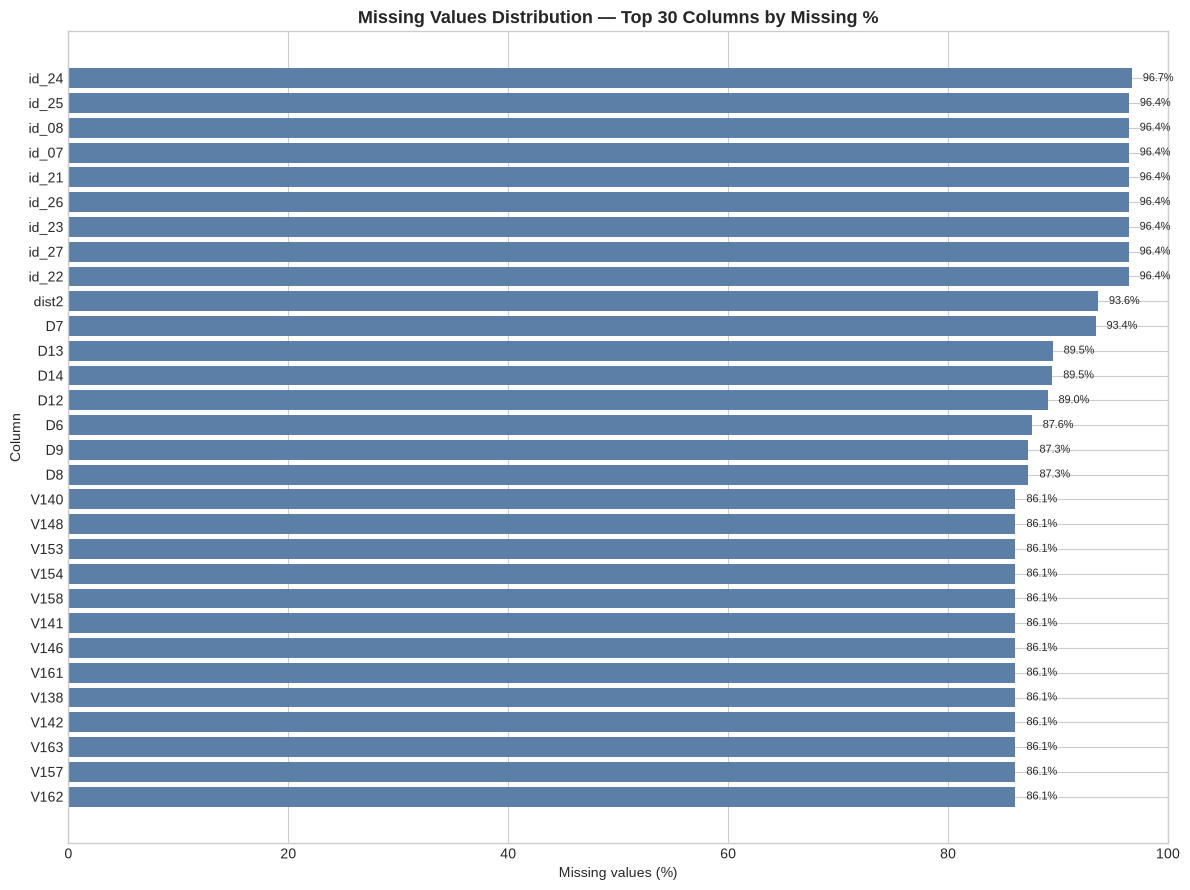

In [14]:
top_miss = missing_all.head(30).sort_values("missing_pct")
fig, ax = plt.subplots(figsize=(12, 9))
ax.barh(top_miss.index.astype(str), top_miss["missing_pct"], color="#5B7FA6")
ax.set_xlabel("Missing values (%)")
ax.set_ylabel("Column")
ax.set_title("Missing Values Distribution — Top 30 Columns by Missing %", fontsize=13, weight="bold")
ax.set_xlim(0, 100)
for i, v in enumerate(top_miss["missing_pct"]):
    ax.text(v + 1, i, f"{v:.1f}%", va="center", fontsize=8)
plt.tight_layout()
plt.savefig(VIZ_DIR / "01_missing_values.png", dpi=300, bbox_inches="tight")
plt.show()

### 11.2 Fraud vs Genuine Transaction Distribution

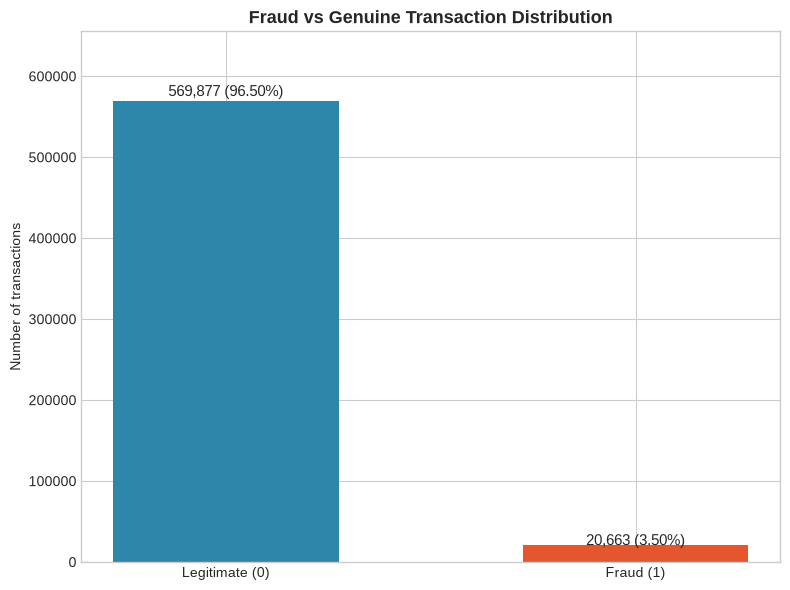

In [15]:
counts = merged["isFraud"].value_counts().sort_index()
labels = ["Legitimate (0)", "Fraud (1)"]
fig, ax = plt.subplots(figsize=(8, 6))
bars = ax.bar(labels, counts.values, color=[LEGIT_COLOR, FRAUD_COLOR], width=0.55)
ax.set_ylabel("Number of transactions")
ax.set_title("Fraud vs Genuine Transaction Distribution", fontsize=13, weight="bold")
for bar, v in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() * 1.01,
            f"{v:,} ({v / len(merged) * 100:.2f}%)", ha="center", fontsize=11)
ax.set_ylim(0, counts.max() * 1.15)
plt.tight_layout()
plt.savefig(VIZ_DIR / "02_fraud_vs_genuine.png", dpi=300, bbox_inches="tight")
plt.show()

### 11.3 Transaction Amount Distribution (log scale)

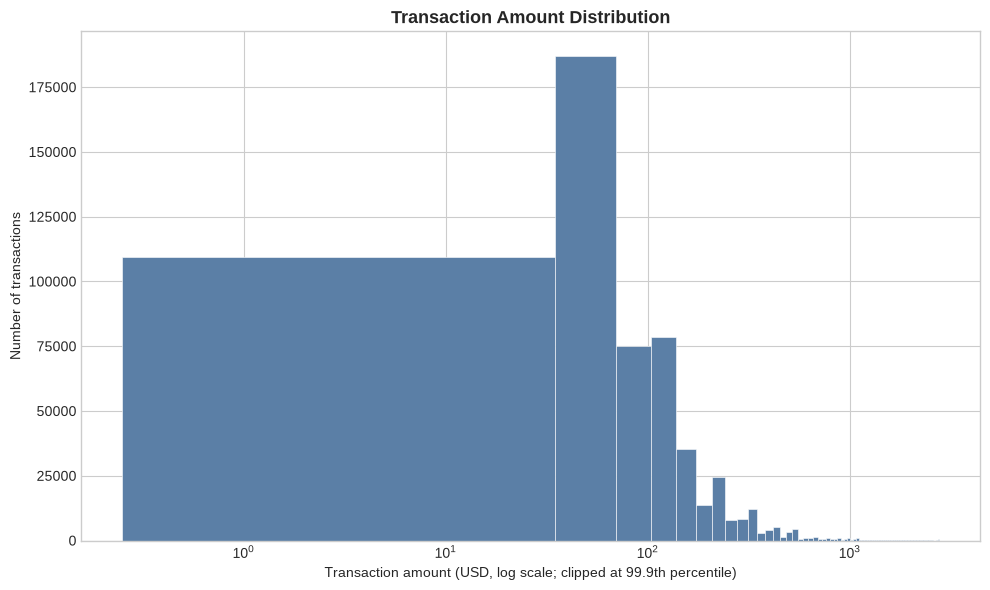

In [16]:
amt = merged["TransactionAmt"].dropna()
upper = amt.quantile(0.999)  # clip the extreme 0.1% only for display
fig, ax = plt.subplots(figsize=(10, 6))
ax.hist(amt.clip(upper=upper), bins=80, color="#5B7FA6", edgecolor="white", linewidth=0.4)
ax.set_xscale("log")
ax.set_xlabel("Transaction amount (USD, log scale; clipped at 99.9th percentile)")
ax.set_ylabel("Number of transactions")
ax.set_title("Transaction Amount Distribution", fontsize=13, weight="bold")
plt.tight_layout()
plt.savefig(VIZ_DIR / "03_transaction_amount_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

### 11.4 Fraud vs Genuine Transaction Amount Comparison

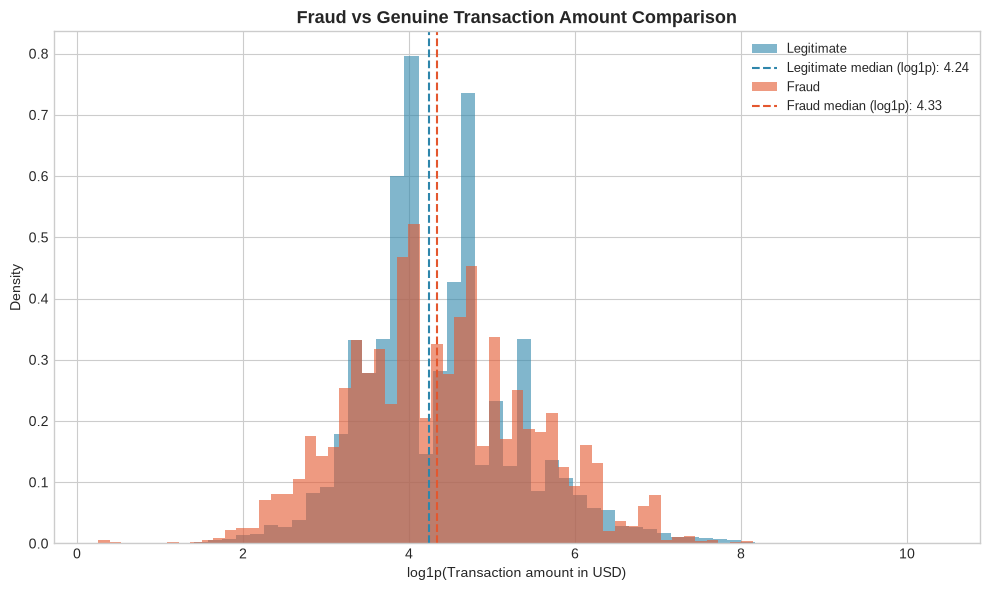

In [17]:
fig, ax = plt.subplots(figsize=(10, 6))
for label, mask, color in [("Legitimate", merged["isFraud"] == 0, LEGIT_COLOR),
                          ("Fraud", merged["isFraud"] == 1, FRAUD_COLOR)]:
    vals = np.log1p(merged.loc[mask, "TransactionAmt"].dropna())
    ax.hist(vals, bins=60, alpha=0.6, label=label, color=color, density=True)
    ax.axvline(vals.median(), color=color, linestyle="--", linewidth=1.5,
               label=f"{label} median (log1p): {vals.median():.2f}")
ax.set_xlabel("log1p(Transaction amount in USD)")
ax.set_ylabel("Density")
ax.set_title("Fraud vs Genuine Transaction Amount Comparison", fontsize=13, weight="bold")
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig(VIZ_DIR / "04_amount_by_fraud.png", dpi=300, bbox_inches="tight")
plt.show()

### 11.5 Fraud Percentage by Product Category

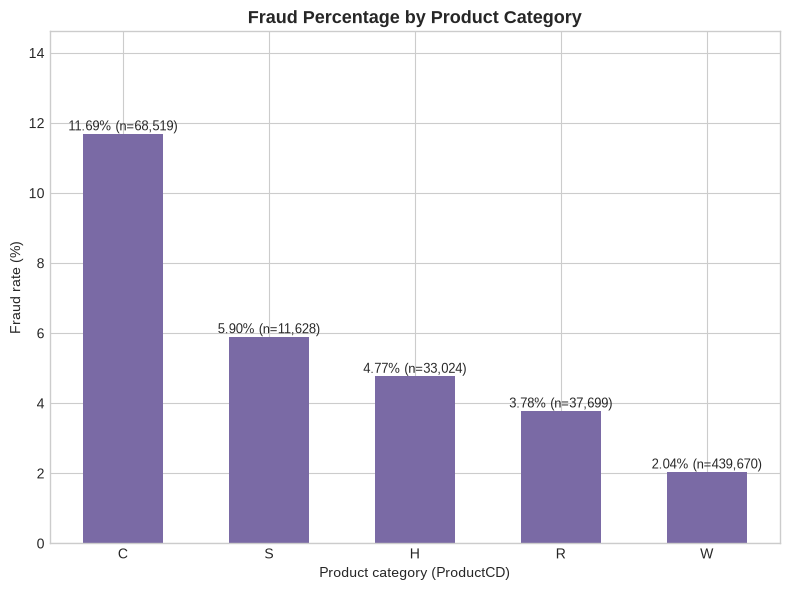

In [18]:
prod = fraud_rate_table(merged, "ProductCD").reset_index()
fig, ax = plt.subplots(figsize=(8, 6))
bars = ax.bar(prod["ProductCD"].astype(str), prod["fraud_rate_pct"], color="#7A6AA5", width=0.55)
ax.set_xlabel("Product category (ProductCD)")
ax.set_ylabel("Fraud rate (%)")
ax.set_title("Fraud Percentage by Product Category", fontsize=13, weight="bold")
for bar, row in zip(bars, prod.itertuples()):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.1,
            f"{row.fraud_rate_pct:.2f}% (n={row.transactions:,})", ha="center", fontsize=9)
ax.set_ylim(0, prod["fraud_rate_pct"].max() * 1.25)
plt.tight_layout()
plt.savefig(VIZ_DIR / "05_fraud_pct_by_product.png", dpi=300, bbox_inches="tight")
plt.show()

### 11.6 Numerical Feature Correlation Heatmap

Correlations among the core numeric features (`TransactionAmt`, `card1/2/3/5`,
`C1..C14`, `D1..D15`). The 339 anonymised `V` features are excluded here —
a 339-column heatmap would be unreadable, and their pairwise correlations
belong to the feature-engineering task.

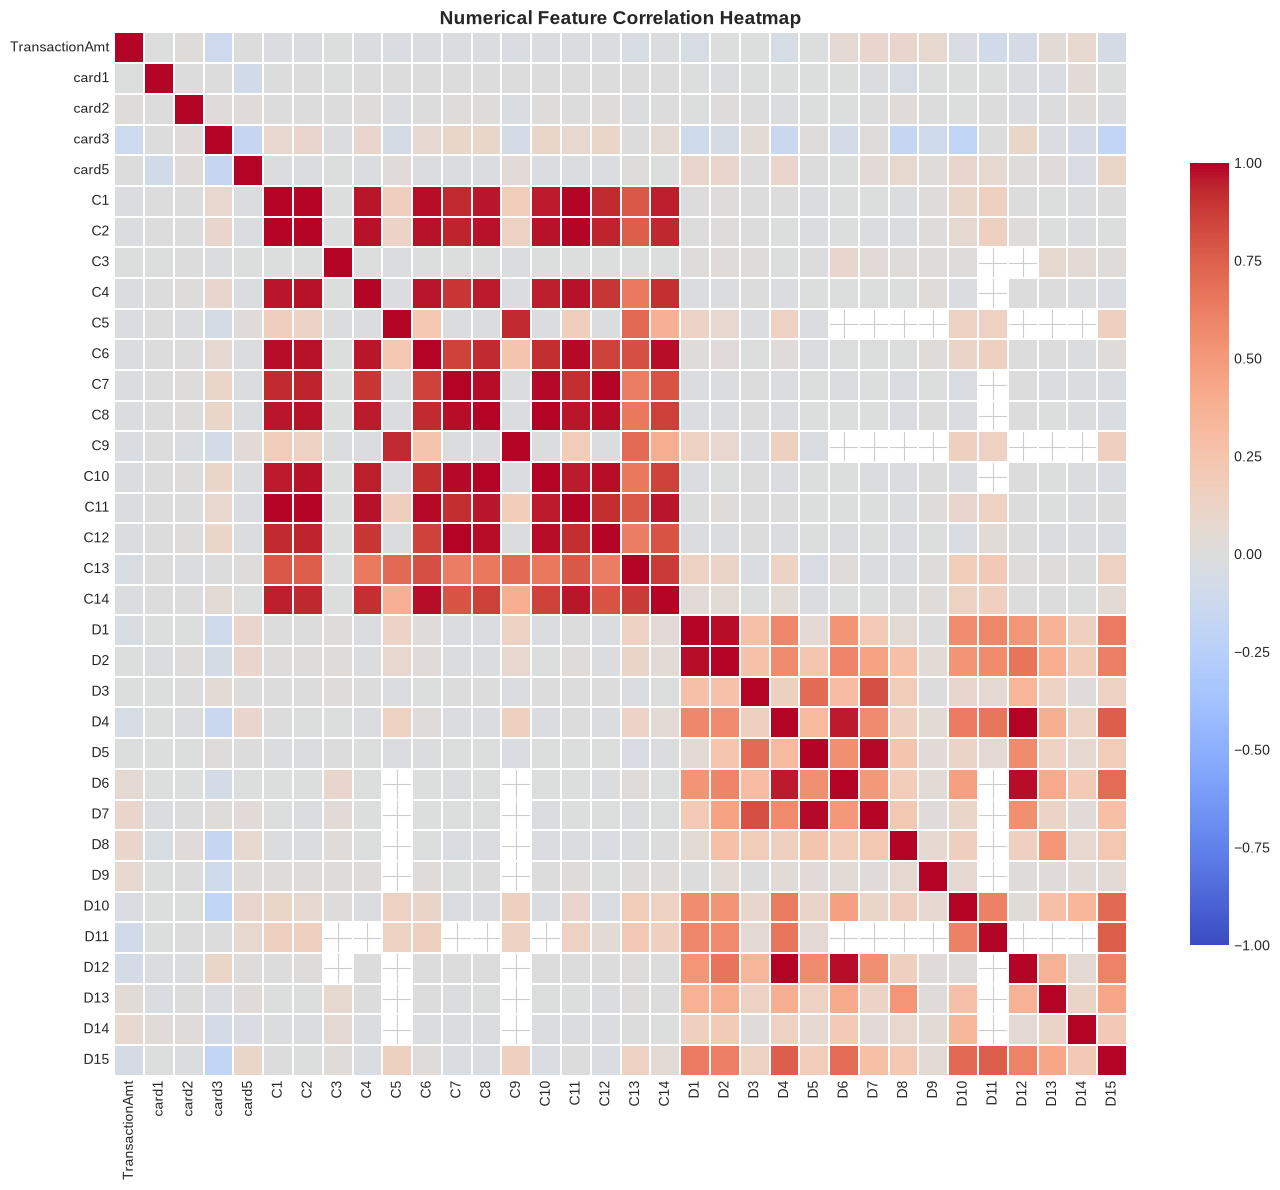

In [19]:
corr_cols = (["TransactionAmt", "card1", "card2", "card3", "card5"]
             + [f"C{i}" for i in range(1, 15)] + [f"D{i}" for i in range(1, 16)])
corr = merged[corr_cols].corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1,
            linewidths=0.3, linecolor="white", cbar_kws={"shrink": 0.75}, ax=ax)
ax.set_title("Numerical Feature Correlation Heatmap", fontsize=14, weight="bold")
plt.tight_layout()
plt.savefig(VIZ_DIR / "06_correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

### 11.7 Outlier Analysis — transaction amount by fraud status

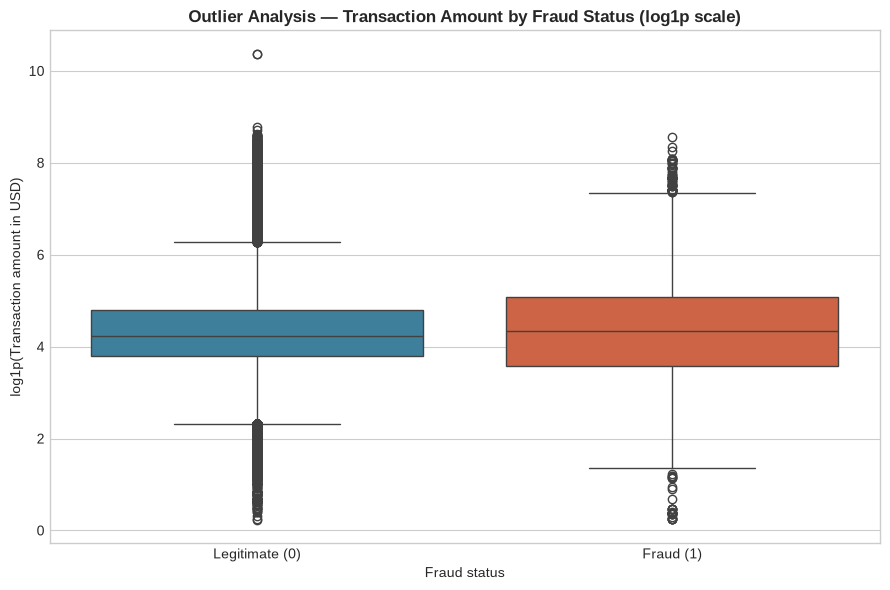

In [20]:
fig, ax = plt.subplots(figsize=(9, 6))
plot_df = merged[["isFraud", "TransactionAmt"]].copy()
plot_df["TransactionAmt"] = np.log1p(plot_df["TransactionAmt"])
sns.boxplot(data=plot_df, x="isFraud", y="TransactionAmt", hue="isFraud",
            palette={0: LEGIT_COLOR, 1: FRAUD_COLOR}, legend=False, ax=ax)
ax.set_xticks([0, 1])
ax.set_xticklabels(["Legitimate (0)", "Fraud (1)"])
ax.set_xlabel("Fraud status")
ax.set_ylabel("log1p(Transaction amount in USD)")
ax.set_title("Outlier Analysis — Transaction Amount by Fraud Status (log1p scale)",
             fontsize=12, weight="bold")
plt.tight_layout()
plt.savefig(VIZ_DIR / "07_outlier_analysis.png", dpi=300, bbox_inches="tight")
plt.show()

### 11.8 Fraud Distribution Across Selected Categorical Features

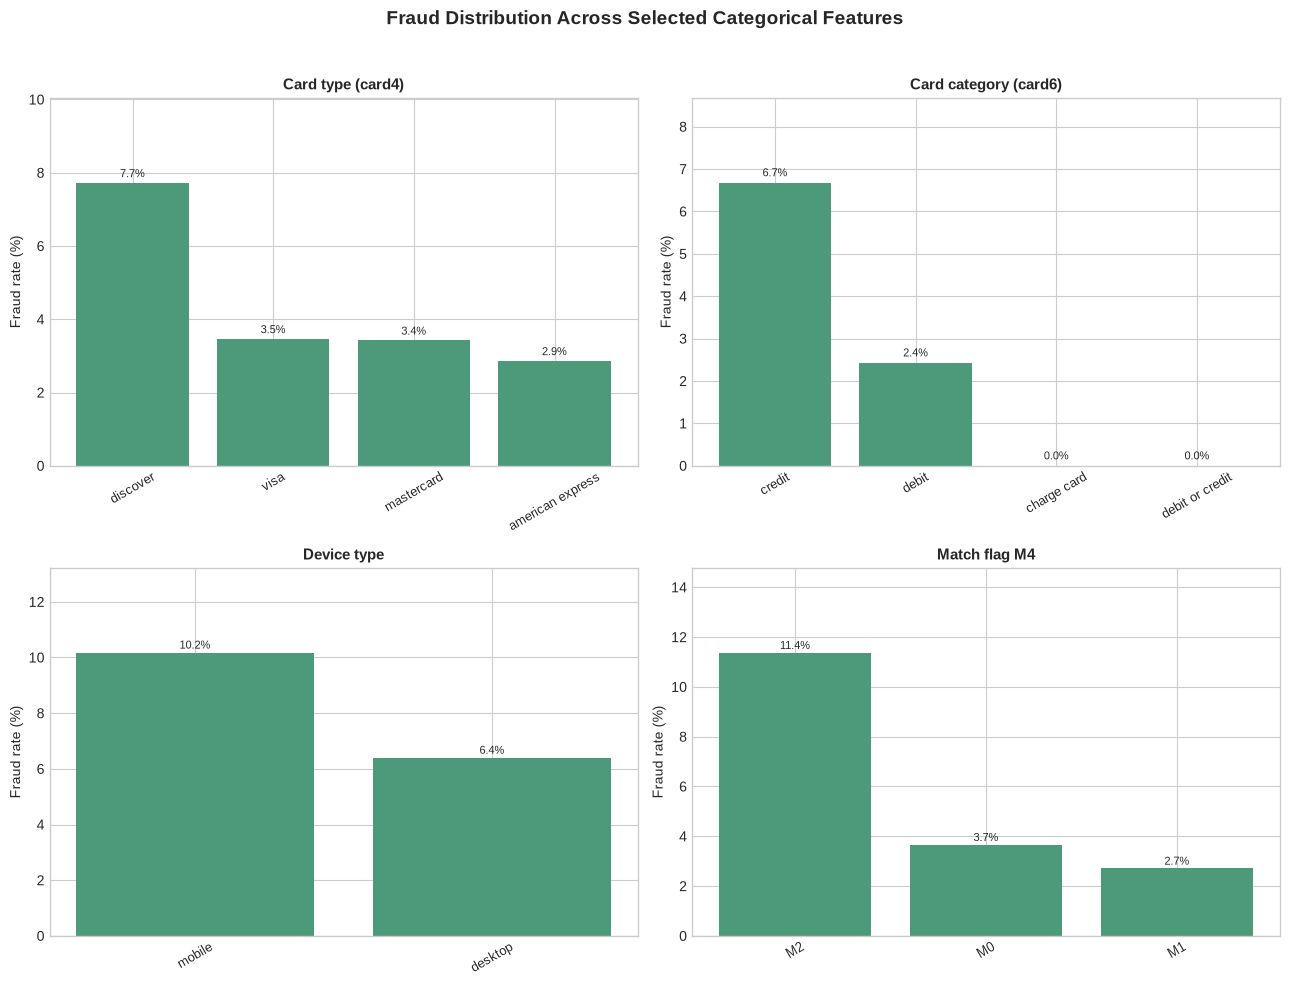

Visualisations saved in /home/hatch/workspace/FinGuard/Task-1-Data-Cleaning/visualizations
  01_missing_values.png — 280 KB
  02_fraud_vs_genuine.png — 91 KB
  03_transaction_amount_distribution.png — 93 KB
  04_amount_by_fraud.png — 119 KB
  05_fraud_pct_by_product.png — 110 KB
  06_correlation_heatmap.png — 248 KB
  07_outlier_analysis.png — 111 KB
  08_fraud_by_categorical.png — 276 KB


In [21]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
panels = [("card4", "Card type (card4)"), ("card6", "Card category (card6)"),
          ("DeviceType", "Device type"), ("M4", "Match flag M4")]
for ax, (col, title) in zip(axes.ravel(), panels):
    t = fraud_rate_table(merged, col).reset_index()
    ax.bar(t[col].astype(str), t["fraud_rate_pct"], color="#4C9A7A")
    ax.set_title(title, fontsize=11, weight="bold")
    ax.set_ylabel("Fraud rate (%)")
    ax.tick_params(axis="x", rotation=30, labelsize=9)
    for bar, row in zip(ax.patches, t.itertuples()):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.15,
                f"{row.fraud_rate_pct:.1f}%", ha="center", fontsize=8)
    ax.set_ylim(0, t["fraud_rate_pct"].max() * 1.3)
fig.suptitle("Fraud Distribution Across Selected Categorical Features", fontsize=14, weight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig(VIZ_DIR / "08_fraud_by_categorical.png", dpi=300, bbox_inches="tight")
plt.show()

print("Visualisations saved in", VIZ_DIR)
for f in sorted(VIZ_DIR.glob("*.png")):
    print(f"  {f.name} — {f.stat().st_size / 1024:,.0f} KB")

## 12. Final Data Validation

Checklist before export: dimensions, `TransactionID` integrity, target
integrity, remaining missing values, duplicates, and readiness for feature
engineering. Remaining missing values are expected — they are the
high-missingness columns deliberately retained in Section 5.

In [22]:
print("--- Final validation ---")
print(f"Final shape: {merged.shape[0]:,} rows x {merged.shape[1]} columns "
      f"(transaction 394 + identity 41 - 1 shared key = 434)")
print("TransactionID unique:", merged["TransactionID"].is_unique,
      "| missing TransactionIDs:", int(merged["TransactionID"].isna().sum()))
print("isFraud values:", sorted(merged["isFraud"].unique().tolist()),
      "| missing:", int(merged["isFraud"].isna().sum()),
      "| fraud rate:", f"{merged['isFraud'].mean() * 100:.2f}%")
print("Full-row duplicates:", int(merged.duplicated().sum()))
miss_final = merged.isna().sum()
print(f"Columns still containing missing values: {int((miss_final > 0).sum())} "
      f"(retained by design, Section 5) | total missing cells: {int(miss_final.sum()):,}")
cols_fully_missing = merged.columns[merged.isna().all()].tolist()
print("Fully-missing columns (would be dropped in a later task if useless):",
      cols_fully_missing if cols_fully_missing else "none")
print()
print("Readiness for Task 2 (feature engineering): YES — one row per transaction, "
      "unique key, clean target, no accidental duplicates, outliers retained as signal.")
assert merged.shape[0] == 590540, "Unexpected row count"
assert merged["TransactionID"].is_unique
assert set(merged["isFraud"].unique().tolist()) == {0, 1}

--- Final validation ---
Final shape: 590,540 rows x 434 columns (transaction 394 + identity 41 - 1 shared key = 434)
TransactionID unique: True | missing TransactionIDs: 0
isFraud values: [0, 1] | missing: 0 | fraud rate: 3.50%


Full-row duplicates: 0


Columns still containing missing values: 322 (retained by design, Section 5) | total missing cells: 115,424,563


Fully-missing columns (would be dropped in a later task if useless): none

Readiness for Task 2 (feature engineering): YES — one row per transaction, unique key, clean target, no accidental duplicates, outliers retained as signal.


## 13. Export Cleaned Dataset

The final merged, cleaned dataset is saved to
`../cleaned_data/merged_cleaned_transactions.csv`. It is intentionally **not**
committed to GitHub (see `.gitignore`) because of its size. No model training,
feature selection, class balancing, train-test splitting or model-specific
encoding was performed — those belong to later tasks.

In [23]:
OUT_PATH = OUT_DIR / "merged_cleaned_transactions.csv"
merged.to_csv(OUT_PATH, index=False)
size_mb = OUT_PATH.stat().st_size / 1024**2
print(f"Saved: {OUT_PATH}")
print(f"File size: {size_mb:,.1f} MB | rows: {merged.shape[0]:,} | columns: {merged.shape[1]}")

# Lightweight re-read check (key + target columns only)
check = pd.read_csv(OUT_PATH, usecols=["TransactionID", "isFraud"])
assert check.shape[0] == merged.shape[0], "Exported row count mismatch"
assert check["TransactionID"].is_unique, "Exported TransactionIDs are not unique"
assert int(check["isFraud"].sum()) == int(merged["isFraud"].sum()), "Fraud count mismatch"
print("Export verified: row count, TransactionID uniqueness and fraud count all match.")
print("\nTask 1 complete: data cleaned, merged, visualised and exported.")

Saved: /home/hatch/workspace/FinGuard/Task-1-Data-Cleaning/cleaned_data/merged_cleaned_transactions.csv
File size: 678.9 MB | rows: 590,540 | columns: 434


Export verified: row count, TransactionID uniqueness and fraud count all match.

Task 1 complete: data cleaned, merged, visualised and exported.
